## Setup: settings, data and backbone

In [53]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.datasets import CelebA
from torchvision.models import resnet18, ResNet18_Weights

# ---------------------------------------------------------------- settings (one per line)
SEED = 0
BATCH_SIZE = 32
LEARNING_RATE = 1e-4       # fine-tuning rate for the pretrained ResNet (Parts 1 and 2)
NUM_EPOCHS = 8             # fine-tuning epochs for Parts 1 and 2; the best epoch is kept
DATA_DIR = "/Volumes/extreme ssd"

N_TRAIN = 5_000            # subset sizes (raise them if your machine allows it)
N_VALID = 1_000
N_TEST = 1_000

USE_HFLIP_AUGMENTATION = True   # random left-right flips, training images only
SAVE_CACHE_TO_DISK = True       # avoids re-reading the JPEGs after a kernel restart
CACHE_FILE = Path(f"celeba64_subset_cache_{N_TRAIN}_{N_VALID}_{N_TEST}_seed{SEED}.pt")

USE_CLASS_WEIGHTS = True        # Part 2: weight rare concepts more in the loss
APPLY_PRIOR_CORRECTION = True   # Part 2: undo the probability shift that class weights cause
NUM_INTERVENTION_ORDERS = 100   # Part 3-4: random concept orders averaged per intervention curve

# ---------------------------------------------------------------- target and concepts
TARGET_ATTR = "Smiling"

CONCEPT_ATTRS = [
    "Mouth_Slightly_Open",
    "High_Cheekbones",
    "Chubby",
    "Narrow_Eyes",
    "Bags_Under_Eyes",
    "Big_Lips",
    "Big_Nose",
    "Pointy_Nose",
    "Bushy_Eyebrows",
    "Arched_Eyebrows",
]
NUM_CONCEPTS = len(CONCEPT_ATTRS)

# The pretrained weights expect ImageNet-normalised inputs. Images stay in [0, 1] outside the
# model (simpler caching, augmentation and plotting); the backbone normalises them itself.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# ---------------------------------------------------------------- device, seed, plot style
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Active execution device: {device}")

torch.manual_seed(SEED)

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 6,
})
# One colour per model, used in every chart below.
MODEL_COLORS = {
    "Baseline (x → y)": "#52514e",
    "Independent CBM": "#2a78d6",
    "Hybrid CBM": "#eb6834",
}

Active execution device: mps


In [54]:
# ---------------------------------------------------------------- data
# Crop first so PyTorch does not squash a rectangular face into a square, then shrink to 64x64.
transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

train_full = CelebA(root=DATA_DIR, split="train", target_type="attr", download=False, transform=transform)
valid_full = CelebA(root=DATA_DIR, split="valid", target_type="attr", download=False, transform=transform)
test_full = CelebA(root=DATA_DIR, split="test", target_type="attr", download=False, transform=transform)
print("Full split sizes - train / valid / test:", len(train_full), len(valid_full), len(test_full))

# Locate the target and the concepts by name among the 40 CelebA attributes.
smiling_index = train_full.attr_names.index(TARGET_ATTR)
concept_indices = [train_full.attr_names.index(name) for name in CONCEPT_ATTRS]


def smiling_labels(attributes):
    """(N,) float 0/1 labels for 'Smiling' from a batch of the 40 attributes."""
    return (attributes[:, smiling_index] == 1).float()


def concept_labels(attributes):
    """(N, 10) float 0/1 labels for the concepts from a batch of the 40 attributes."""
    return (attributes[:, concept_indices] == 1).float()


# Random (but seeded) subsets, so every model uses exactly the same images.
subset_generator = torch.Generator().manual_seed(SEED)


def take_subset(full_dataset, size):
    assert 1 <= size <= len(full_dataset)
    indices = torch.randperm(len(full_dataset), generator=subset_generator)[:size].tolist()
    return Subset(full_dataset, indices)


train_subset = take_subset(train_full, N_TRAIN)
valid_subset = take_subset(valid_full, N_VALID)
test_subset = take_subset(test_full, N_TEST)


# Decode the JPEGs once and keep them as uint8 (exact: ToTensor() is uint8 / 255).
@torch.no_grad()
def cache_split(subset, split_name, batch_size=256):
    loader = DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=0)
    images, attributes = [], []
    for batch_number, (batch_images, batch_attributes) in enumerate(loader, start=1):
        images.append(batch_images.mul(255).round().to(torch.uint8))
        attributes.append(batch_attributes)
        if batch_number == 1 or batch_number % 10 == 0 or batch_number == len(loader):
            print(f"Caching {split_name} | batch {batch_number}/{len(loader)}", flush=True)
    return torch.cat(images), torch.cat(attributes)


subset_indices = {
    "train": torch.tensor(train_subset.indices),
    "valid": torch.tensor(valid_subset.indices),
    "test": torch.tensor(test_subset.indices),
}

cache = None
if SAVE_CACHE_TO_DISK and CACHE_FILE.exists():
    cache = torch.load(CACHE_FILE)
    if all(torch.equal(cache[f"{split}_indices"], indices) for split, indices in subset_indices.items()):
        print("Loaded cached images from", CACHE_FILE)
    else:
        print("Cache does not match the current subsets; rebuilding it.")
        cache = None

if cache is None:
    cache = {}
    for split, subset in [("train", train_subset), ("valid", valid_subset), ("test", test_subset)]:
        cache[f"{split}_images"], cache[f"{split}_attributes"] = cache_split(subset, split)
        cache[f"{split}_indices"] = subset_indices[split]
    if SAVE_CACHE_TO_DISK:
        torch.save(cache, CACHE_FILE)
        print("Saved cache to", CACHE_FILE)


class CachedImages(Dataset):
    """Cached uint8 images served as float tensors in [0, 1], with optional random flips."""

    def __init__(self, images, attributes, hflip=False):
        self.images = images
        self.attributes = attributes
        self.hflip = hflip

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index].float().div(255)
        if self.hflip and torch.rand(()) < 0.5:
            image = image.flip(-1)
        return image, self.attributes[index]


# Every loader returns (images, all 40 attributes); the label helpers above pick the columns.
train_loader = DataLoader(
    CachedImages(cache["train_images"], cache["train_attributes"], hflip=USE_HFLIP_AUGMENTATION),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
# Same training images, unshuffled and unaugmented: used to read off frozen outputs in Parts 3-4.
train_eval_loader = DataLoader(
    CachedImages(cache["train_images"], cache["train_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
valid_loader = DataLoader(
    CachedImages(cache["valid_images"], cache["valid_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
test_loader = DataLoader(
    CachedImages(cache["test_images"], cache["test_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

train_attributes = cache["train_attributes"]
print("Subset sizes - train / valid / test:",
      len(train_loader.dataset), len(valid_loader.dataset), len(test_loader.dataset))
print(f"Smiling prevalence - train: {smiling_labels(train_attributes).mean():.3f}, "
      f"valid: {smiling_labels(cache['valid_attributes']).mean():.3f}, "
      f"test: {smiling_labels(cache['test_attributes']).mean():.3f}")

Full split sizes - train / valid / test: 162770 19867 19962
Loaded cached images from celeba64_subset_cache_5000_1000_1000_seed0.pt
Subset sizes - train / valid / test: 5000 1000 1000
Smiling prevalence - train: 0.473, valid: 0.472, test: 0.538


In [55]:
# ---------------------------------------------------------------- shared backbone
class SharedResNetBackbone(nn.Module):
    """
    Feature extractor shared by every model: an ImageNet-pretrained ResNet-18 without its
    1000-class fc layer. It takes images in [0, 1], normalises them with the ImageNet
    statistics, and returns a 512-dimensional feature vector per image.
    """

    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        resnet = resnet18(weights=weights)

        self.in_features = resnet.fc.in_features  # 512

        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

        # Remove the original fc layer by slicing up to (and including) the average pool.
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

    def forward(self, x):
        x = (x - self.mean) / self.std
        features = self.backbone(x)
        return torch.flatten(features, 1)  # shape: (N, 512)


# Every part builds its own SharedResNetBackbone(pretrained=True), so each experiment starts from
# the ImageNet weights and re-running a cell never continues from an earlier run.

## Evaluation toolkit (used by every part)

- `binary_scores`: accuracy at logit 0 (P = 0.5) and the threshold-free AUROC.
- `bootstrap_ci`: 95% intervals by resampling the test images. With about 1,000 test images, accuracy is only known to roughly ±2 percentage points, so a point estimate alone can mislead.
- `paired_difference_ci`: the difference between two models **on the same resampled images**. This is more sensitive than checking whether two separate intervals overlap.
- `BestCheckpoint`: remembers the weights of the epoch with the best validation score.

In [56]:
def binary_scores(y_true, logits):
    """Accuracy at P = 0.5 (logit 0) and threshold-free AUROC."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    logits = np.asarray(logits, dtype=float).reshape(-1)
    return {
        "accuracy": float(((logits >= 0) == y_true).mean()),
        "auroc": float(roc_auc_score(y_true, logits)),
    }


@torch.no_grad()
def predict_logits(model, loader):
    """(labels, logits) on the CPU for a model that maps images to one Smiling logit."""
    model.eval()
    all_labels, all_logits = [], []
    for images, attributes in loader:
        all_logits.append(model(images.to(device)).float().cpu())
        all_labels.append(smiling_labels(attributes))
    return torch.cat(all_labels), torch.cat(all_logits)


def evaluate(model, loader):
    y_true, logits = predict_logits(model, loader)
    return binary_scores(y_true, logits)


def bootstrap_ci(y_true, logits, n_boot=1000, seed=0):
    """95% percentile-bootstrap intervals for accuracy and AUROC (resampling test images)."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    logits = np.asarray(logits, dtype=float).reshape(-1)
    rng = np.random.default_rng(seed)
    accuracies, aurocs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        accuracies.append(((logits[idx] >= 0) == y_true[idx]).mean())
        aurocs.append(roc_auc_score(y_true[idx], logits[idx]))
    return np.percentile(accuracies, [2.5, 97.5]), np.percentile(aurocs, [2.5, 97.5])


def paired_difference_ci(y_true, logits_a, logits_b, n_boot=1000, seed=0):
    """Point estimate and 95% bootstrap CI of (model A - model B) on the SAME test images."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    a = np.asarray(logits_a, dtype=float).reshape(-1)
    b = np.asarray(logits_b, dtype=float).reshape(-1)
    rng = np.random.default_rng(seed)
    accuracy_differences, auroc_differences = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        yb = y_true[idx]
        if yb.min() == yb.max():
            continue
        accuracy_differences.append(((a[idx] >= 0) == yb).mean() - ((b[idx] >= 0) == yb).mean())
        auroc_differences.append(roc_auc_score(yb, a[idx]) - roc_auc_score(yb, b[idx]))
    scores_a, scores_b = binary_scores(y_true, a), binary_scores(y_true, b)
    return {
        "accuracy_difference": scores_a["accuracy"] - scores_b["accuracy"],
        "accuracy_ci": np.percentile(accuracy_differences, [2.5, 97.5]),
        "auroc_difference": scores_a["auroc"] - scores_b["auroc"],
        "auroc_ci": np.percentile(auroc_differences, [2.5, 97.5]),
    }


def print_difference(name_a, name_b, d):
    print(f"{name_a} minus {name_b}: "
          f"accuracy {100 * d['accuracy_difference']:+.2f} pp "
          f"(95% CI {100 * d['accuracy_ci'][0]:+.2f} to {100 * d['accuracy_ci'][1]:+.2f}); "
          f"AUROC {d['auroc_difference']:+.4f} "
          f"(95% CI {d['auroc_ci'][0]:+.4f} to {d['auroc_ci'][1]:+.4f})")


def score_row(name, y_true, logits):
    """One summary-table row with bootstrap 95% CIs."""
    scores = binary_scores(y_true, logits)
    accuracy_ci, auroc_ci = bootstrap_ci(y_true, logits)
    return {
        "Model": name,
        "Test accuracy": scores["accuracy"],
        "Accuracy 95% CI": f"[{accuracy_ci[0]:.3f}, {accuracy_ci[1]:.3f}]",
        "Test AUROC": scores["auroc"],
        "AUROC 95% CI": f"[{auroc_ci[0]:.3f}, {auroc_ci[1]:.3f}]",
    }


class BestCheckpoint:
    """Keeps the weights from the epoch with the highest validation score (stored on the CPU)."""

    def __init__(self):
        self.score = float("-inf")
        self.state = None
        self.epoch = None

    def update(self, score, model, epoch):
        if score > self.score:
            self.score, self.epoch = score, epoch
            self.state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

    def restore(self, model, total_epochs):
        model.load_state_dict(self.state)
        print(f"Restored epoch {self.epoch} (best validation score {self.score:.4f})")
        if self.epoch == total_epochs:
            print("Note: the last epoch was best; NUM_EPOCHS may be too small.")

---
# Part 1: Baseline classifier (x → y)

A standard image classifier: the shared ResNet-18 backbone followed by a single linear head that outputs one **logit** per image. The logit is not a probability yet; `BCEWithLogitsLoss` applies the sigmoid inside the loss.

Report: test accuracy and test AUROC (with confidence intervals).

In [57]:
class BaselineClassifier(nn.Module):
    def __init__(self, backbone, num_classes=1):
        super().__init__()
        self.backbone = backbone
        self.classifier = nn.Linear(backbone.in_features, num_classes)

    def forward(self, x):
        features = self.backbone(x)                    # (N, 512)
        return self.classifier(features).squeeze(-1)   # (N,) logits


torch.manual_seed(SEED)
baseline_model = BaselineClassifier(SharedResNetBackbone(pretrained=True), num_classes=1).to(device)

criterion_y = nn.BCEWithLogitsLoss()                                    # sigmoid + binary cross-entropy
optimizer_y = optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)  # one adaptive learning rate per parameter
checkpoint_y = BestCheckpoint()
history_y = []

print("--- Training Baseline Classifier (x -> y) ---")
for epoch in range(NUM_EPOCHS):
    baseline_model.train()
    running_loss = 0.0

    for images, attributes in train_loader:
        images, targets = images.to(device), smiling_labels(attributes).to(device)

        optimizer_y.zero_grad()                  # clear the gradient from the previous batch
        logits = baseline_model(images)          # forward pass
        loss = criterion_y(logits, targets)
        loss.backward()                          # backward pass
        optimizer_y.step()                       # update the weights

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    valid_metrics = evaluate(baseline_model, valid_loader)
    history_y.append({"Epoch": epoch + 1, "Train BCE": epoch_loss,
                      "Validation accuracy": valid_metrics["accuracy"],
                      "Validation AUROC": valid_metrics["auroc"]})
    checkpoint_y.update(valid_metrics["auroc"], baseline_model, epoch + 1)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Loss: {epoch_loss:.4f} | "
          f"Validation accuracy: {valid_metrics['accuracy']:.4f} | "
          f"Validation AUROC: {valid_metrics['auroc']:.4f}")

# Go back to the epoch that did best on the validation images (not the last one).
checkpoint_y.restore(baseline_model, NUM_EPOCHS)

--- Training Baseline Classifier (x -> y) ---
Epoch [1/8] - Loss: 0.4889 | Validation accuracy: 0.8520 | Validation AUROC: 0.9335
Epoch [2/8] - Loss: 0.2349 | Validation accuracy: 0.8880 | Validation AUROC: 0.9621
Epoch [3/8] - Loss: 0.1570 | Validation accuracy: 0.8780 | Validation AUROC: 0.9504
Epoch [4/8] - Loss: 0.1316 | Validation accuracy: 0.8950 | Validation AUROC: 0.9615
Epoch [5/8] - Loss: 0.0835 | Validation accuracy: 0.9060 | Validation AUROC: 0.9633
Epoch [6/8] - Loss: 0.0686 | Validation accuracy: 0.9100 | Validation AUROC: 0.9644
Epoch [7/8] - Loss: 0.0518 | Validation accuracy: 0.8980 | Validation AUROC: 0.9569
Epoch [8/8] - Loss: 0.0514 | Validation accuracy: 0.9010 | Validation AUROC: 0.9579
Restored epoch 6 (best validation score 0.9644)


In [58]:
# Keep the test logits: every later model is compared with these, image by image.
baseline_test_y, baseline_test_logits = predict_logits(baseline_model, test_loader)
baseline_test_metrics = binary_scores(baseline_test_y, baseline_test_logits)
accuracy_ci, auroc_ci = bootstrap_ci(baseline_test_y, baseline_test_logits)

print("=== Baseline Classifier (x -> y) Report ===")
print(f"Test accuracy: {baseline_test_metrics['accuracy']:.2%}  (95% CI {accuracy_ci[0]:.1%} - {accuracy_ci[1]:.1%})")
print(f"Test AUROC:    {baseline_test_metrics['auroc']:.4f}  (95% CI {auroc_ci[0]:.4f} - {auroc_ci[1]:.4f})")
display(pd.DataFrame(history_y).round(4))

=== Baseline Classifier (x -> y) Report ===
Test accuracy: 88.80%  (95% CI 86.9% - 90.8%)
Test AUROC:    0.9610  (95% CI 0.9499 - 0.9704)


,Epoch,Train BCE,Validation accuracy,Validation AUROC
0,1,0.4889,0.852,0.9335
1,2,0.2349,0.888,0.9621
2,3,0.1570,0.878,0.9504
3,4,0.1316,0.895,0.9615
4,5,0.0835,0.906,0.9633
5,6,0.0686,0.910,0.9644
6,7,0.0518,0.898,0.9569
7,8,0.0514,0.901,0.9579


#### Part 1: notes
- Typically the training loss keeps falling while the validation AUROC flattens out: with a few thousand images the network starts to memorise the training set. That is why the checkpoint is chosen on **validation** AUROC and why the test images are only used at the very end.
- Report the confidence interval, not just the point estimate (see the toolkit note above).
- This model is the reference for Parts 3–4. Its test logits (`baseline_test_logits`) are kept so that later comparisons are *paired* on identical images.

---
# Part 2: Concept predictor (x → c)

A multi-label model: the shared backbone followed by one linear layer with 10 outputs (equivalent to one independent binary head per concept), trained with binary cross-entropy.

Report: per-concept performance and the macro-average.

In [59]:
class ConceptPredictor(nn.Module):
    def __init__(self, backbone, num_concepts=10):
        super().__init__()
        self.backbone = backbone
        self.concept_head = nn.Linear(backbone.in_features, num_concepts)

    def forward(self, x):
        features = self.backbone(x)           # (N, 512)
        return self.concept_head(features)    # (N, 10) raw logits


# Class balance of each concept in the TRAINING labels only.
train_concept_labels = concept_labels(train_attributes)
positive_counts = train_concept_labels.sum(dim=0)
negative_counts = len(train_concept_labels) - positive_counts

if USE_CLASS_WEIGHTS:
    if (positive_counts == 0).any() or (negative_counts == 0).any():
        raise ValueError("Each concept needs positive and negative training examples. "
                         "Increase the training subset size or change the seed.")
    concept_pos_weight = negative_counts / positive_counts
else:
    concept_pos_weight = torch.ones(NUM_CONCEPTS)

# pos_weight = w counts every positive example w times, so the loss is minimised by predicting odds
# w times too high: the logits end up shifted by about +log(w). Subtracting log(w) when predicting
# (a "prior correction") undoes the shift but keeps the benefit of weighting during training.
if APPLY_PRIOR_CORRECTION:
    concept_logit_offset = torch.log(concept_pos_weight).float()
else:
    concept_logit_offset = torch.zeros(NUM_CONCEPTS)

display(pd.DataFrame({
    "Concept": CONCEPT_ATTRS,
    "Training positives": positive_counts.int().tolist(),
    "Training negatives": negative_counts.int().tolist(),
    "Prevalence": (positive_counts / len(train_concept_labels)).tolist(),
    "Positive weight w": concept_pos_weight.tolist(),
    "Logit shift log(w)": concept_logit_offset.tolist(),
}).round(3))

,Concept,Training positives,Training negatives,Prevalence,Positive weight w,Logit shift log(w)
0,Mouth_Slightly_Open,2337,2663,0.467,1.139,0.131
1,High_Cheekbones,2237,2763,0.447,1.235,0.211
2,Chubby,265,4735,0.053,17.868,2.883
3,Narrow_Eyes,596,4404,0.119,7.389,2.000
4,Bags_Under_Eyes,1049,3951,0.210,3.766,1.326
5,Big_Lips,1171,3829,0.234,3.270,1.185
6,Big_Nose,1213,3787,0.243,3.122,1.138
7,Pointy_Nose,1366,3634,0.273,2.660,0.978
8,Bushy_Eyebrows,705,4295,0.141,6.092,1.807
9,Arched_Eyebrows,1355,3645,0.271,2.690,0.990


In [60]:
# ---------------------------------------------------------------- concept metrics
def concept_scores(y_true, y_pred, y_score=None):
    """Per-concept scores and their unweighted macro-averages.

    y_true, y_pred: (n, K) arrays of 0/1. y_score (optional): (n, K) probabilities for AUROC.
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    accuracy = (y_true == y_pred).mean(axis=0)   # column-wise, not "all ten labels correct"
    f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    balanced_accuracy = np.array([
        balanced_accuracy_score(y_true[:, j], y_pred[:, j]) for j in range(y_true.shape[1])
    ])
    prevalence = y_true.mean(axis=0)
    # Accuracy of always predicting the more common value: the bar any classifier must clear.
    majority_accuracy = np.maximum(prevalence, 1 - prevalence)

    result = {
        "accuracy": accuracy,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy,
        "majority_accuracy": majority_accuracy,
        "predicted_positive_rate": y_pred.mean(axis=0),
        "macro_accuracy": float(accuracy.mean()),
        "macro_f1": float(f1.mean()),
        "macro_balanced_accuracy": float(balanced_accuracy.mean()),
        "positive_support": y_true.sum(axis=0),
    }
    if y_score is not None:
        y_score = np.asarray(y_score, dtype=float)
        auroc = np.array([
            roc_auc_score(y_true[:, j], y_score[:, j]) if 0 < prevalence[j] < 1 else np.nan
            for j in range(y_true.shape[1])
        ])
        result["auroc"] = auroc
        result["macro_auroc"] = float(np.nanmean(auroc))
    return result


@torch.no_grad()
def predict_concept_logits(model, loader):
    """Raw concept logits (n, K) and true concept labels (n, K), on the CPU."""
    model.eval()
    all_logits, all_labels = [], []
    for images, attributes in loader:
        all_logits.append(model(images.to(device)).float().cpu())
        all_labels.append(concept_labels(attributes))
    return torch.cat(all_logits), torch.cat(all_labels)


def scores_from_concept_logits(logits, labels, logit_offset=None, thresholds=0.5):
    """Concept metrics from raw logits; logit_offset applies the prior correction."""
    if logit_offset is not None:
        logits = logits - logit_offset
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= torch.as_tensor(thresholds, dtype=probabilities.dtype)).int()
    return concept_scores(labels.numpy(), predictions.numpy(), probabilities.numpy())

In [61]:
torch.manual_seed(SEED)
concept_model = ConceptPredictor(SharedResNetBackbone(pretrained=True), num_concepts=NUM_CONCEPTS).to(device)

criterion_c = nn.BCEWithLogitsLoss(pos_weight=concept_pos_weight.to(device))  # handles all 10 outputs at once
optimizer_c = optim.Adam(concept_model.parameters(), lr=LEARNING_RATE)
checkpoint_c = BestCheckpoint()
history_c = []

# The checkpoint is chosen on mean validation AUROC of the prior-corrected probabilities:
# it is threshold-free, and it scores exactly the probabilities that the CBM will consume.
print("--- Training Concept Predictor (x -> c) ---")
for epoch in range(NUM_EPOCHS):
    concept_model.train()
    running_loss = 0.0

    for images, attributes in train_loader:
        images, concept_targets = images.to(device), concept_labels(attributes).to(device)

        optimizer_c.zero_grad()
        logits = concept_model(images)
        loss = criterion_c(logits, concept_targets)
        loss.backward()
        optimizer_c.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    valid_logits, valid_labels = predict_concept_logits(concept_model, valid_loader)
    valid_metrics = scores_from_concept_logits(valid_logits, valid_labels, concept_logit_offset)
    history_c.append({"Epoch": epoch + 1, "Train weighted BCE": epoch_loss,
                      "Validation mean AUROC": valid_metrics["macro_auroc"],
                      "Validation macro-F1": valid_metrics["macro_f1"],
                      "Validation macro-accuracy": valid_metrics["macro_accuracy"]})
    checkpoint_c.update(valid_metrics["macro_auroc"], concept_model, epoch + 1)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] - Loss: {epoch_loss:.4f} | "
          f"Validation mean AUROC: {valid_metrics['macro_auroc']:.4f} | "
          f"macro-F1: {valid_metrics['macro_f1']:.4f} | "
          f"macro-accuracy: {valid_metrics['macro_accuracy']:.4f}")

checkpoint_c.restore(concept_model, NUM_EPOCHS)
#concept_model.eval()

--- Training Concept Predictor (x -> c) ---
Epoch [1/8] - Loss: 0.9774 | Validation mean AUROC: 0.7698 | macro-F1: 0.3959 | macro-accuracy: 0.8092
Epoch [2/8] - Loss: 0.7643 | Validation mean AUROC: 0.8000 | macro-F1: 0.4361 | macro-accuracy: 0.8248
Epoch [3/8] - Loss: 0.6512 | Validation mean AUROC: 0.8077 | macro-F1: 0.4476 | macro-accuracy: 0.8265
Epoch [4/8] - Loss: 0.5673 | Validation mean AUROC: 0.8068 | macro-F1: 0.4633 | macro-accuracy: 0.8289
Epoch [5/8] - Loss: 0.5007 | Validation mean AUROC: 0.8060 | macro-F1: 0.4661 | macro-accuracy: 0.8258
Epoch [6/8] - Loss: 0.4183 | Validation mean AUROC: 0.8010 | macro-F1: 0.4511 | macro-accuracy: 0.8257
Epoch [7/8] - Loss: 0.3657 | Validation mean AUROC: 0.8120 | macro-F1: 0.4965 | macro-accuracy: 0.8277
Epoch [8/8] - Loss: 0.3040 | Validation mean AUROC: 0.8013 | macro-F1: 0.4880 | macro-accuracy: 0.8203
Restored epoch 7 (best validation score 0.8120)


#### Why class-weighted probabilities need correcting before they enter a CBM

With `pos_weight = w`, each positive example counts `w` times in the loss, so the best the model can do is to predict odds `w` times the true odds: its logits are shifted by about `+log(w)`. The outputs are calibrated to a balanced 50/50 world, not to the real prevalence of each concept. Two consequences:

1. **Accuracy at 0.5 stops being a meaningful concept metric.** For a rare concept the model raises many false alarms, so its accuracy can fall *below* the trivial answer "always absent" (1 − prevalence), even though it ranks images well. Compare the *Always-majority accuracy* column below; F1, balanced accuracy and AUROC are the fairer measures.
2. **The CBM's label head would see inputs from a different distribution.** The independent CBM's label head is trained on true 0/1 concepts at their real frequencies, but at test time it receives predicted probabilities. If those are inflated, the head is fed inputs unlike anything it was trained on.

The fix is the prior correction `σ(logit − log w)`. The next cell checks it on validation data: after the correction the mean predicted probability should be close to the true prevalence and the (unweighted) cross-entropy should drop.

References: King & Zeng (2001), *Logistic Regression in Rare Events Data*; Saerens et al. (2002), *Adjusting the Outputs of a Classifier to New a Priori Probabilities*; Menon et al. (2021, ICLR), *Long-tail Learning via Logit Adjustment*.

In [62]:
concept_valid_logits, concept_valid_labels = predict_concept_logits(concept_model, valid_loader)
raw_probabilities = torch.sigmoid(concept_valid_logits)
corrected_probabilities = torch.sigmoid(concept_valid_logits - concept_logit_offset)

raw_bce = F.binary_cross_entropy(raw_probabilities, concept_valid_labels, reduction="none").mean(dim=0)
corrected_bce = F.binary_cross_entropy(corrected_probabilities, concept_valid_labels, reduction="none").mean(dim=0)

display(pd.DataFrame({
    "Concept": CONCEPT_ATTRS,
    "Validation prevalence": concept_valid_labels.mean(dim=0).numpy(),
    "Mean P (as trained)": raw_probabilities.mean(dim=0).numpy(),
    "Mean P (corrected)": corrected_probabilities.mean(dim=0).numpy(),
    "BCE (as trained)": raw_bce.numpy(),
    "BCE (corrected)": corrected_bce.numpy(),
}).round(3))
print(f"Mean unweighted validation BCE - as trained: {raw_bce.mean():.4f} | corrected: {corrected_bce.mean():.4f}")

,Concept,Validation prevalence,Mean P (as trained),Mean P (corrected),BCE (as trained),BCE (corrected)
0,Mouth_Slightly_Open,0.466,0.488,0.475,0.379,0.377
1,High_Cheekbones,0.445,0.466,0.444,0.446,0.444
2,Chubby,0.067,0.114,0.032,0.235,0.237
3,Narrow_Eyes,0.066,0.209,0.077,0.390,0.252
4,Bags_Under_Eyes,0.189,0.342,0.201,0.580,0.474
5,Big_Lips,0.190,0.348,0.199,0.619,0.524
6,Big_Nose,0.237,0.360,0.235,0.530,0.463
7,Pointy_Nose,0.292,0.392,0.253,0.684,0.656
8,Bushy_Eyebrows,0.127,0.222,0.118,0.331,0.261
9,Arched_Eyebrows,0.272,0.381,0.273,0.493,0.440


Mean unweighted validation BCE - as trained: 0.4686 | corrected: 0.4127


In [63]:
concept_test_logits, concept_test_labels = predict_concept_logits(concept_model, test_loader)

# (a) As trained: class-weighted probabilities at 0.5.
as_trained_test_metrics = scores_from_concept_logits(concept_test_logits, concept_test_labels)
# (b) Prior-corrected probabilities at 0.5: the most likely value of each concept.
concept_test_metrics = scores_from_concept_logits(concept_test_logits, concept_test_labels, concept_logit_offset)

# (c) Per-concept thresholds that maximise F1, chosen on VALIDATION data only.
threshold_grid = np.linspace(0.05, 0.95, 91)
valid_corrected = corrected_probabilities.numpy()
valid_true = concept_valid_labels.numpy().astype(int)
f1_thresholds = np.array([
    threshold_grid[np.argmax([
        f1_score(valid_true[:, j], (valid_corrected[:, j] >= t).astype(int), zero_division=0)
        for t in threshold_grid
    ])]
    for j in range(NUM_CONCEPTS)
])
tuned_test_metrics = scores_from_concept_logits(
    concept_test_logits, concept_test_labels, concept_logit_offset,
    thresholds=torch.tensor(f1_thresholds, dtype=torch.float32),
)

display(pd.DataFrame({
    "Concept": CONCEPT_ATTRS,
    "Test positives": concept_test_metrics["positive_support"].astype(int),
    "AUROC": concept_test_metrics["auroc"],
    "Accuracy (as trained)": as_trained_test_metrics["accuracy"],
    "Accuracy (corrected)": concept_test_metrics["accuracy"],
    "Always-majority accuracy": concept_test_metrics["majority_accuracy"],
    "Balanced acc. (corrected)": concept_test_metrics["balanced_accuracy"],
    "F1 (corrected, 0.5)": concept_test_metrics["f1"],
    "F1 (val-tuned threshold)": tuned_test_metrics["f1"],
    "Tuned threshold": f1_thresholds,
}).round(3))

display(pd.DataFrame([
    {"Predictions": name,
     "Macro accuracy": metrics["macro_accuracy"],
     "Macro balanced accuracy": metrics["macro_balanced_accuracy"],
     "Macro F1": metrics["macro_f1"],
     "Mean AUROC": metrics["macro_auroc"]}
    for name, metrics in [
        ("As trained, threshold 0.5", as_trained_test_metrics),
        ("Corrected, threshold 0.5", concept_test_metrics),
        ("Corrected, val-tuned thresholds", tuned_test_metrics),
    ]
]).round(4))

majority = concept_test_metrics["majority_accuracy"]
print(f"Always-majority macro accuracy: {majority.mean():.4f}")
print(f"Concepts whose accuracy is below the always-majority baseline: "
      f"as trained {int((as_trained_test_metrics['accuracy'] < majority).sum())}/{NUM_CONCEPTS}, "
      f"corrected {int((concept_test_metrics['accuracy'] < majority).sum())}/{NUM_CONCEPTS}")

,Concept,Test positives,AUROC,Accuracy (as trained),Accuracy (corrected),Always-majority accuracy,Balanced acc. (corrected),"F1 (corrected, 0.5)",F1 (val-tuned threshold),Tuned threshold
0,Mouth_Slightly_Open,512,0.900,0.836,0.833,0.512,0.833,0.834,0.822,0.41
1,High_Cheekbones,501,0.905,0.822,0.822,0.501,0.822,0.819,0.833,0.34
2,Chubby,61,0.877,0.921,0.942,0.939,0.578,0.256,0.472,0.09
3,Narrow_Eyes,131,0.744,0.818,0.872,0.869,0.560,0.220,0.389,0.13
4,Bags_Under_Eyes,193,0.795,0.737,0.799,0.807,0.657,0.449,0.497,0.17
5,Big_Lips,306,0.640,0.650,0.689,0.694,0.558,0.301,0.485,0.12
6,Big_Nose,224,0.818,0.751,0.803,0.776,0.698,0.536,0.545,0.18
7,Pointy_Nose,296,0.689,0.670,0.709,0.704,0.597,0.395,0.522,0.09
8,Bushy_Eyebrows,149,0.847,0.825,0.878,0.851,0.726,0.555,0.556,0.41
9,Arched_Eyebrows,268,0.806,0.739,0.773,0.732,0.698,0.559,0.584,0.26


,Predictions,Macro accuracy,Macro balanced accuracy,Macro F1,Mean AUROC
0,"As trained, threshold 0.5",0.7769,0.7262,0.5658,0.8023
1,"Corrected, threshold 0.5",0.8120,0.6727,0.4925,0.8023
2,"Corrected, val-tuned thresholds",0.7568,0.7165,0.5704,0.8023


Always-majority macro accuracy: 0.7385
Concepts whose accuracy is below the always-majority baseline: as trained 7/10, corrected 2/10


#### Part 2: notes
- **Which metric?** Accuracy looks high for most concepts simply because most faces do not have a rare attribute, so "not present" is usually right (compare with the always-majority column). F1 (state the threshold), balanced accuracy and AUROC show how well each concept is really detected.
- **Class weighting is a trade-off.** It raises recall on rare concepts but miscalibrates the probabilities. In a CBM the probabilities *are* the bottleneck, so calibration matters as much as ranking quality. Check the calibration table above.
- **Not all concepts are equally learnable.** Concepts such as `Mouth_Slightly_Open` and `High_Cheekbones` have plenty of clear examples and are visually obvious; subjective attributes such as `Big_Lips`, `Pointy_Nose` or `Narrow_Eyes` are widely regarded as noisy CelebA labels, and 64×64 images make fine details harder still. What matters most for Part 3 is the quality of the concepts that carry the Smiling signal (see the label-head weights).
- With only a few thousand training images, rare concepts are the weakest link. More training data is the first thing to try if the CBM underperforms because of its concepts.

---
# Part 3: Concept Bottleneck Model (x → c → y)

So far the baseline is a black box. Here the prediction has to pass through the 10 concepts: a frozen concept predictor feeds a linear layer that sees **only** those concepts. The label head's weights then explain every decision.

### Training strategy: Independent CBM (Koh et al., 2020)
- **x → c** is the Part 2 concept predictor, frozen (weights *and* BatchNorm statistics).
- **c → y** is a logistic regression trained on the **true** training concepts, never on the predictor's outputs.
- **At test time** the label head receives the predicted, prior-corrected concept probabilities, which match the real concept frequencies the head was trained on.

The label head is a convex problem with 11 parameters, so it is fitted to convergence with L-BFGS: there is no epoch count to tune.

Report: test accuracy and AUROC, concept metrics, and a quantitative comparison with the baseline.

In [64]:
if "baseline_test_logits" not in globals() or "concept_test_metrics" not in globals():
    raise RuntimeError("Run the Part 1 and Part 2 cells before Part 3.")


class IndependentCBM(nn.Module):
    """x -> c -> y. The concept predictor is frozen; the label head only sees the concepts."""

    def __init__(self, concept_predictor, num_concepts=10, concept_logit_offset=None):
        super().__init__()
        # Feature 1: the trained x -> c concept predictor, frozen.
        self.concept_predictor = concept_predictor
        self.concept_predictor.requires_grad_(False)
        self.concept_predictor.eval()

        # Prior correction for class-weighted concept logits (zeros = no correction).
        if concept_logit_offset is None:
            concept_logit_offset = torch.zeros(num_concepts)
        self.register_buffer("concept_logit_offset", concept_logit_offset.detach().clone().float())

        # Feature 2: the bottleneck layer mapping concepts to the target (c -> y).
        self.c_to_y = nn.Linear(num_concepts, 1)

    def train(self, mode=True):
        # Freezing the weights alone does not freeze BatchNorm statistics, so keep the predictor in eval mode.
        super().train(mode)
        self.concept_predictor.eval()
        return self

    @torch.no_grad()
    def predict_concepts(self, images):
        # The concept probabilities the label head receives at test time.
        concept_logits = self.concept_predictor(images) - self.concept_logit_offset
        return torch.sigmoid(concept_logits)

    def forward(self, images):
        concept_probs = self.predict_concepts(images)
        return self.c_to_y(concept_probs).squeeze(-1)   # (N,) Smiling logits


def fit_linear_head(inputs, targets, offset=None, weight_decay=1e-4, output_penalty=0.0, max_iter=500):
    """Fits logits = offset + Linear(inputs) with full-batch L-BFGS on the CPU (a convex problem).

    weight_decay:   L2 penalty on the weights.
    output_penalty: penalty on the mean squared output of this head. Part 4 uses it to limit how much
                    the side channel may contribute to the final logit.
    """
    inputs = inputs.detach().float().cpu()
    targets = targets.detach().float().cpu()
    offset = torch.zeros(len(targets)) if offset is None else offset.detach().float().cpu()

    head = nn.Linear(inputs.shape[1], 1)
    nn.init.zeros_(head.weight)
    nn.init.zeros_(head.bias)
    optimizer = torch.optim.LBFGS(head.parameters(), lr=1.0, max_iter=max_iter,
                                  history_size=50, line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        head_output = head(inputs).squeeze(-1)
        loss = F.binary_cross_entropy_with_logits(offset + head_output, targets)
        loss = loss + weight_decay * head.weight.pow(2).sum()
        if output_penalty > 0:
            loss = loss + output_penalty * head_output.pow(2).mean()
        loss.backward()
        return loss

    optimizer.step(closure)
    head.requires_grad_(False)
    return head


@torch.no_grad()
def head_logits(head, inputs):
    return head(inputs).squeeze(-1)

In [65]:
# One pass of the frozen concept predictor over each split. Parts 3 and 4 reuse these outputs,
# so nothing below has to push images through the network again.
@torch.no_grad()
def collect_frozen_outputs(concept_predictor, loader, split_name):
    concept_predictor.eval()
    features, logits, true_concepts, targets = [], [], [], []
    for images, attributes in loader:
        batch_features = concept_predictor.backbone(images.to(device))
        features.append(batch_features.float().cpu())
        logits.append(concept_predictor.concept_head(batch_features).float().cpu())
        true_concepts.append(concept_labels(attributes))
        targets.append(smiling_labels(attributes))

    outputs = {
        "features": torch.cat(features),
        "concept_logits": torch.cat(logits),
        "true_concepts": torch.cat(true_concepts),
        "target": torch.cat(targets),
    }
    outputs["soft_concepts"] = torch.sigmoid(outputs["concept_logits"] - concept_logit_offset)  # predicted concepts
    outputs["concept_predictions"] = (outputs["soft_concepts"] >= 0.5).float()  # only for concept metrics
    print(f"{split_name}: cached frozen outputs for {len(outputs['target'])} images")
    return outputs


frozen = {
    "train": collect_frozen_outputs(concept_model, train_eval_loader, "Train"),
    "valid": collect_frozen_outputs(concept_model, valid_loader, "Validation"),
    "test": collect_frozen_outputs(concept_model, test_loader, "Test"),
}


def mean_concept_auroc(split):
    data = frozen[split]
    return concept_scores(data["true_concepts"].numpy(), data["concept_predictions"].numpy(),
                          data["soft_concepts"].numpy())["macro_auroc"]


# The Part 4 side head is trained on frozen outputs for TRAINING images, where the predictor is more
# accurate than on new images (it was fine-tuned on them). This shows how large that gap is.
print(f"Mean concept AUROC - training images: {mean_concept_auroc('train'):.3f} | "
      f"validation images: {mean_concept_auroc('valid'):.3f}")

Train: cached frozen outputs for 5000 images
Validation: cached frozen outputs for 1000 images
Test: cached frozen outputs for 1000 images
Mean concept AUROC - training images: 0.986 | validation images: 0.812


In [66]:
# c -> y is fitted on the TRUE training concepts (never on the predictor's outputs).
independent_head = fit_linear_head(frozen["train"]["true_concepts"], frozen["train"]["target"])

test_y = frozen["test"]["target"]
assert torch.equal(test_y.long(), baseline_test_y.long()), "Test images must be in the same order."

# At test time the head takes the predicted concept probabilities.
main_logits = head_logits(independent_head, frozen["test"]["soft_concepts"])

# The full image -> prediction model, built from the trained pieces.
cbm_model = IndependentCBM(copy.deepcopy(concept_model), NUM_CONCEPTS, concept_logit_offset).to(device)
cbm_model.c_to_y.load_state_dict(independent_head.state_dict())
cbm_model.eval()

# Sanity check: the full module reproduces the cached computation used for the results below.
_, cbm_module_logits = predict_logits(cbm_model, test_loader)
max_gap = (cbm_module_logits - main_logits).abs().max().item()
assert max_gap < 1e-3, f"Module and cached path disagree (max |delta logit| = {max_gap:.2e})"
print(f"Sanity check passed: full CBM and cached computation agree (max |delta logit| = {max_gap:.1e}).")

Sanity check passed: full CBM and cached computation agree (max |delta logit| = 1.4e-06).


In [67]:
display(pd.DataFrame([
    score_row("Baseline (x → y)", test_y, baseline_test_logits),
    score_row("Independent CBM (x → c → y)", test_y, main_logits),
]).round(4))

print_difference("CBM", "baseline", paired_difference_ci(test_y, main_logits, baseline_test_logits))

cbm_test_metrics = binary_scores(test_y, main_logits)
cbm_concept_test_metrics = concept_scores(
    frozen["test"]["true_concepts"].numpy(),
    frozen["test"]["concept_predictions"].numpy(),
    frozen["test"]["soft_concepts"].numpy(),
)

display(pd.DataFrame({
    "Concept": CONCEPT_ATTRS,
    "Accuracy": cbm_concept_test_metrics["accuracy"],
    "F1": cbm_concept_test_metrics["f1"],
    "AUROC": cbm_concept_test_metrics["auroc"],
    "Test positives": cbm_concept_test_metrics["positive_support"].astype(int),
}).round(4))
print(f"CBM concept macro-accuracy: {cbm_concept_test_metrics['macro_accuracy']:.4f} | "
      f"macro-F1: {cbm_concept_test_metrics['macro_f1']:.4f} | "
      f"mean AUROC: {cbm_concept_test_metrics['macro_auroc']:.4f}")
print("Identical to Part 2 (corrected, threshold 0.5)?",
      np.allclose(cbm_concept_test_metrics["f1"], concept_test_metrics["f1"]),
      "- expected, because an independent CBM reuses the frozen concept predictor unchanged.")

,Model,Test accuracy,Accuracy 95% CI,Test AUROC,AUROC 95% CI
0,Baseline (x → y),0.888,"[0.869, 0.908]",0.9610,"[0.950, 0.970]"
1,Independent CBM (x → c → y),0.827,"[0.802, 0.849]",0.9058,"[0.886, 0.924]"


CBM minus baseline: accuracy -6.10 pp (95% CI -8.40 to -3.80); AUROC -0.0552 (95% CI -0.0704 to -0.0403)


,Concept,Accuracy,F1,AUROC,Test positives
0,Mouth_Slightly_Open,0.833,0.8342,0.9002,512
1,High_Cheekbones,0.822,0.8187,0.9055,501
2,Chubby,0.942,0.2564,0.8774,61
3,Narrow_Eyes,0.872,0.2195,0.7442,131
4,Bags_Under_Eyes,0.799,0.4493,0.7952,193
5,Big_Lips,0.689,0.3011,0.6396,306
6,Big_Nose,0.803,0.5365,0.8182,224
7,Pointy_Nose,0.709,0.3950,0.6892,296
8,Bushy_Eyebrows,0.878,0.5547,0.8468,149
9,Arched_Eyebrows,0.773,0.5592,0.8062,268


CBM concept macro-accuracy: 0.8120 | macro-F1: 0.4925 | mean AUROC: 0.8023
Identical to Part 2 (corrected, threshold 0.5)? True - expected, because an independent CBM reuses the frozen concept predictor unchanged.


### Interpretability: the label head is the explanation
Each weight says how much a concept pushes the Smiling logit up or down. Check that the explanation is plausible (for Smiling, `High_Cheekbones` and `Mouth_Slightly_Open` would be expected to dominate with positive weights) and look out for weights that act as proxies rather than causes.

,Concept,Weight,Concept test AUROC,Odds ratio
1,High_Cheekbones,3.247,0.905,25.718
0,Mouth_Slightly_Open,2.164,0.900,8.709
6,Big_Nose,0.606,0.818,1.833
4,Bags_Under_Eyes,0.470,0.795,1.600
8,Bushy_Eyebrows,0.348,0.847,1.417
5,Big_Lips,-0.348,0.640,0.706
2,Chubby,-0.325,0.877,0.722
7,Pointy_Nose,0.262,0.689,1.300
9,Arched_Eyebrows,-0.111,0.806,0.895
3,Narrow_Eyes,0.080,0.744,1.083


Intercept: -2.817


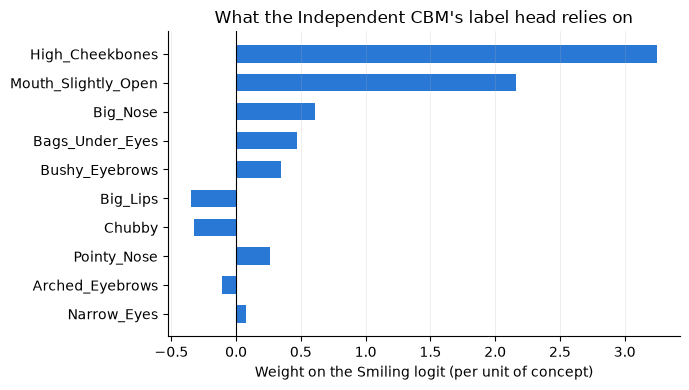

In [68]:
weights_report = pd.DataFrame({
    "Concept": CONCEPT_ATTRS,
    "Weight": independent_head.weight.squeeze(0).numpy(),
    "Concept test AUROC": cbm_concept_test_metrics["auroc"],
})
weights_report["Odds ratio"] = np.exp(weights_report["Weight"])
weights_report = weights_report.sort_values("Weight", key=np.abs, ascending=False)
display(weights_report.round(3))
print(f"Intercept: {independent_head.bias.item():+.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
positions = np.arange(NUM_CONCEPTS)
ax.barh(positions, weights_report["Weight"], height=0.6, color=MODEL_COLORS["Independent CBM"])
ax.set_yticks(positions)
ax.set_yticklabels(weights_report["Concept"])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Weight on the Smiling logit (per unit of concept)")
ax.set_title("What the Independent CBM's label head relies on")
plt.tight_layout()
plt.show()

### Steerability: test-time interventions (Koh et al., §6; Havasi et al., Fig. 2)

A human who knows the true value of some concepts can overwrite the model's predictions for them. For every test image we replace the predicted values of *k* concepts with their ground-truth 0/1 labels and recompute the Smiling prediction, for *k* = 0 … 10. Concepts are chosen in random order, and each curve averages `NUM_INTERVENTION_ORDERS` random orders (the same orders for every model, so Part 4 can reuse them). At *k* = 10 every concept comes from the human, so the label head sees exactly the kind of input it was trained on.

What to expect (Koh et al., Fig. 4): because the label head was trained on true concepts, accuracy should rise steadily as more concepts are corrected.

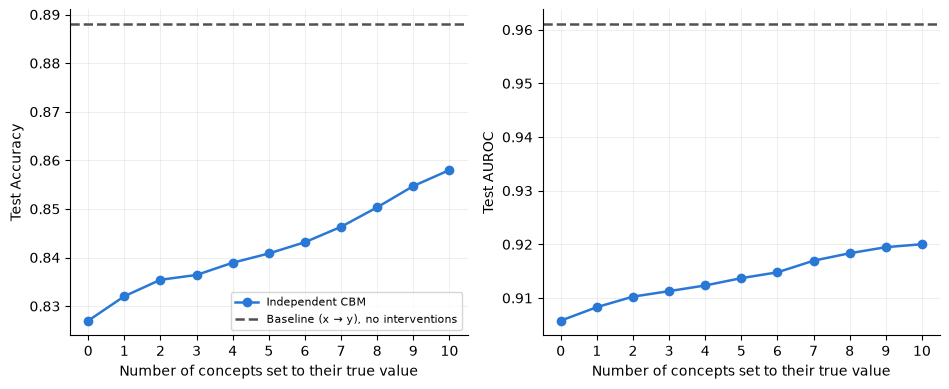

,"Accuracy, k=0","Accuracy, k=2","Accuracy, k=5","Accuracy, k=10",Gain k=0 → all (pp)
Independent CBM,0.827,0.8354,0.8408,0.858,3.1


In [69]:
@torch.no_grad()
def intervention_curve(score_fn, predicted_concepts, true_concepts, targets,
                       n_orders=NUM_INTERVENTION_ORDERS, seed=0):
    """Mean test accuracy/AUROC/RMSE when k random concepts are set to their true values.

    score_fn maps an (n, K) concept matrix to (n,) logits. RMSE is the root of the Brier score:
    the RMSE between P(Smiling) and the 0/1 label (0 = perfect, 0.5 = always answering 0.5).
    """
    rng = np.random.default_rng(seed)  # same seed -> same concept orders for every model
    y = targets.float()
    k_max = predicted_concepts.shape[1]
    accuracy = np.zeros((n_orders, k_max + 1))
    auroc = np.zeros((n_orders, k_max + 1))
    rmse = np.zeros((n_orders, k_max + 1))
    for r in range(n_orders):
        order = torch.as_tensor(rng.permutation(k_max), dtype=torch.long)
        for k in range(k_max + 1):
            concepts = predicted_concepts.clone()
            if k > 0:
                chosen = order[:k]
                concepts[:, chosen] = true_concepts[:, chosen]
            logits = score_fn(concepts)
            scores = binary_scores(targets, logits)
            accuracy[r, k], auroc[r, k] = scores["accuracy"], scores["auroc"]
            rmse[r, k] = torch.sqrt((torch.sigmoid(logits) - y).pow(2).mean()).item()
    return pd.DataFrame({
        "Concepts intervened": np.arange(k_max + 1),
        "Accuracy": accuracy.mean(axis=0),
        "AUROC": auroc.mean(axis=0),
        "RMSE": rmse.mean(axis=0),
    })


def plot_interventions(results, baseline_scores, metrics=("Accuracy", "AUROC")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.8 * len(metrics), 4))
    for axis, metric in zip(np.atleast_1d(axes), metrics):
        for name, curve in results.items():
            axis.plot(curve["Concepts intervened"], curve[metric], marker="o",
                      color=MODEL_COLORS[name], label=name)
        axis.axhline(baseline_scores[metric.lower()], color=MODEL_COLORS["Baseline (x → y)"],
                     linestyle="--", label="Baseline (x → y), no interventions")
        axis.set_xticks(range(NUM_CONCEPTS + 1))
        axis.set_xlabel("Number of concepts set to their true value")
        axis.set_ylabel(f"Test {metric}")
    np.atleast_1d(axes)[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def intervention_table(results):
    ks = sorted({0, min(2, NUM_CONCEPTS), min(5, NUM_CONCEPTS), NUM_CONCEPTS})
    table = pd.DataFrame({
        name: curve.set_index("Concepts intervened")["Accuracy"].loc[ks]
        for name, curve in results.items()
    }).T
    table.columns = [f"Accuracy, k={k}" for k in ks]
    table["Gain k=0 → all (pp)"] = 100 * (table.iloc[:, -1] - table.iloc[:, 0])
    return table


test_frozen = frozen["test"]
intervention_results = {
    "Independent CBM": intervention_curve(
        lambda c: head_logits(independent_head, c),
        test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y),
}

plot_interventions(intervention_results, baseline_test_metrics)
display(intervention_table(intervention_results).round(4))

#### Part 3: how to read these results
The gap between the CBM and the baseline splits into two parts, both visible in the intervention table:
1. **All concepts intervened (k = 10) vs. the baseline:** can *any* CBM on these 10 concepts match the baseline? If even the label head fed with the true concepts falls short, that part of the gap is structural: Smiling is not fully determined by these concepts. Neither reference paper claims CBMs beat end-to-end models: Koh et al. report the independent bottleneck *worse* than the standard model on CUB (24.0% vs. 17.5% error) and competitive on OAI, where the concepts are the clinical criteria that define the label.
2. **No interventions (k = 0) vs. all concepts intervened:** the cost of predicting the concepts from 64×64 images. This part shrinks as the concept predictor improves, and it is also how much a human can recover by correcting the concepts (steerability).

Garbage in, garbage out: a label head can only be as good as the concept probabilities it receives, which is why the weak concepts from Part 2 limit the CBM when the training subset is small. And a bottleneck always discards whatever information in the image is not captured by the 10 concepts, which motivates the side channel in Part 4.

---
# Part 4: Hybrid CBM with a side channel

To avoid the information loss of the bottleneck, the label is predicted from two pathways whose logits are summed:

**y = f(c) + s(x)**

- `f(c)`: the concept-based classifier, exactly the Part 3 label head (`f_c`, fixed). The concepts, their weights and the meaning of an intervention are identical to Part 3.
- `s(x)`: a linear side-channel head (`s_x`) on the 512-d backbone features, i.e. the image after the network has interpreted it but *before* it is squeezed into 10 concepts.

**The hook.** The features `s(x)` needs are an intermediate tensor inside the concept predictor (the output of its `avgpool` layer). A PyTorch *forward hook* grabs that tensor during the normal forward pass, so the concept predictor does not have to be modified.

**The side-channel penalty λ.** The side head is trained to minimise `BCE + λ · mean(s(x)²)`. With λ = 0 the side channel takes whatever helps; as λ grows, `s(x)` → 0 and the pure CBM is recovered. Koh et al. (§8) flag the risk this controls: an unconstrained x → y path can reason about the concepts itself, so editing the concepts no longer controls the output.

For each λ we record predictive performance, **how much of the decision comes from the concepts** (side-channel share of |logit|, and how often the concept path alone reaches the same decision), and **steerability** (accuracy when all 10 concepts are set to their true values).

In [70]:
if "cbm_test_metrics" not in globals() or "independent_head" not in globals():
    raise RuntimeError("Run Part 3 before Part 4.")


class HybridCBM(nn.Module):
    """logit = f_c(concept probabilities) + s_x(backbone features), with the features taken by a hook."""

    def __init__(self, concept_predictor, num_concepts=10, feature_dim=512, concept_logit_offset=None):
        super().__init__()
        self.concept_predictor = concept_predictor
        self.concept_predictor.requires_grad_(False)   # frozen again
        self.concept_predictor.eval()

        if concept_logit_offset is None:
            concept_logit_offset = torch.zeros(num_concepts)
        self.register_buffer("concept_logit_offset", concept_logit_offset.detach().clone().float())

        # Pathway 1: f(c), the concept-based linear classifier (10 -> 1).
        self.f_c = nn.Linear(num_concepts, 1)
        # Pathway 2: s(x), the side-channel linear classifier on the backbone features (512 -> 1).
        self.s_x = nn.Linear(feature_dim, 1)

        # Buffer for the 512-d features captured by the hook.
        self.extracted_features = None

        def hook_fn(module, inputs, output):
            # Intercept the tensor right after pooling and flatten it to (batch_size, 512).
            self.extracted_features = torch.flatten(output, 1)

        # Find the average-pool layer automatically: it is the last point where the image has been
        # fully processed by the network but nothing has been squeezed into concepts yet.
        for name, module in self.concept_predictor.named_modules():
            if isinstance(module, nn.AdaptiveAvgPool2d):
                module.register_forward_hook(hook_fn)
                print(f"[HybridCBM] Hooked into backbone layer: '{name}'")
                break
        else:
            raise RuntimeError("Could not find an average-pool layer in the concept predictor.")

    def train(self, mode=True):
        super().train(mode)
        self.concept_predictor.eval()   # keep the BatchNorm statistics fixed
        return self

    def forward(self, x):
        # 1. The concept predictor's forward pass also fills self.extracted_features through the hook.
        concept_logits = self.concept_predictor(x) - self.concept_logit_offset
        concept_probs = torch.sigmoid(concept_logits)
        features = self.extracted_features

        # 2. Logits of both pathways; the final decision is their sum.
        f_c_logit = self.f_c(concept_probs)   # (N, 1)
        s_x_logit = self.s_x(features)        # (N, 1)
        return (f_c_logit + s_x_logit).squeeze(-1)


# The side head is fitted on standardised features (a better-conditioned problem and comparable
# penalties across features). The standardisation is folded back into the weights afterwards, so the
# HybridCBM above stays a plain pair of linear layers.
feature_mean = frozen["train"]["features"].mean(dim=0)
feature_std = frozen["train"]["features"].std(dim=0).clamp_min(1e-6)


def fold_standardization(head, mean, std):
    """Linear head on standardised features -> equivalent Linear head on raw features."""
    folded = nn.Linear(head.in_features, 1)
    with torch.no_grad():
        folded.weight.copy_(head.weight / std)
        folded.bias.copy_(head.bias - (head.weight / std * mean).sum())
    return folded


with torch.no_grad():
    standardized = {split: (frozen[split]["features"] - feature_mean) / feature_std for split in frozen}
concept_path = {split: head_logits(independent_head, frozen[split]["soft_concepts"]) for split in frozen}
print("Side-channel inputs (train):", tuple(standardized["train"].shape))

Side-channel inputs (train): (5000, 512)


### Fitting the side channel and sweeping λ
The side head is fitted *on top of* the fixed concept path (the concept logit enters the loss as an offset). First its L2 regularisation is chosen on validation AUROC with λ = 0, then λ is swept.

In [71]:
SIDE_WEIGHT_DECAYS = [1e-4, 1e-3, 1e-2]                  # regularisation of the 512-d side head
SIDE_PENALTIES = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]   # lambda: how much the side channel may contribute


def fit_side_head(weight_decay, output_penalty):
    return fit_linear_head(
        standardized["train"], frozen["train"]["target"], offset=concept_path["train"],
        weight_decay=weight_decay, output_penalty=output_penalty,
    )


def side_logits(head, split):
    return head_logits(head, standardized[split])


# Step 1: side-head regularisation, chosen on validation AUROC with lambda = 0.
decay_rows = []
for weight_decay in SIDE_WEIGHT_DECAYS:
    head = fit_side_head(weight_decay, 0.0)
    scores = binary_scores(frozen["valid"]["target"], concept_path["valid"] + side_logits(head, "valid"))
    decay_rows.append({"Weight decay": weight_decay,
                       "Validation AUROC": scores["auroc"],
                       "Validation accuracy": scores["accuracy"]})
decay_report = pd.DataFrame(decay_rows)
display(decay_report.round(4))
SIDE_WEIGHT_DECAY = float(decay_report.loc[decay_report["Validation AUROC"].idxmax(), "Weight decay"])
print("Selected side-head weight decay:", SIDE_WEIGHT_DECAY)

# Step 2: sweep the side-channel penalty lambda.
all_true_concept_path_test = head_logits(independent_head, frozen["test"]["true_concepts"])


def tradeoff_row(penalty, side_valid, side_test):
    f_test = concept_path["test"]
    test_scores = binary_scores(test_y, f_test + side_test)
    intervened = binary_scores(test_y, all_true_concept_path_test + side_test)
    side_size, concept_size = side_test.abs().mean().item(), f_test.abs().mean().item()
    return {
        "λ (side penalty)": penalty,
        "Validation AUROC": binary_scores(frozen["valid"]["target"], concept_path["valid"] + side_valid)["auroc"],
        "Test accuracy": test_scores["accuracy"],
        "Test AUROC": test_scores["auroc"],
        "Side share of |logit|": side_size / (side_size + concept_size),
        "Decisions explained by concepts": ((f_test >= 0) == (f_test + side_test >= 0)).float().mean().item(),
        "Accuracy, all concepts intervened": intervened["accuracy"],
        "Intervention gain (pp)": 100 * (intervened["accuracy"] - test_scores["accuracy"]),
    }


side_heads = {}
tradeoff_rows = []
for penalty in SIDE_PENALTIES:
    side_heads[penalty] = fit_side_head(SIDE_WEIGHT_DECAY, penalty)
    tradeoff_rows.append(tradeoff_row(penalty, side_logits(side_heads[penalty], "valid"),
                                      side_logits(side_heads[penalty], "test")))
# lambda = infinity: no side channel, i.e. the pure independent CBM.
tradeoff_rows.append(tradeoff_row(float("inf"), torch.zeros(len(frozen["valid"]["target"])),
                                  torch.zeros(len(test_y))))
tradeoff_report = pd.DataFrame(tradeoff_rows)
display(tradeoff_report.round(4))

,Weight decay,Validation AUROC,Validation accuracy
0,0.0001,0.9013,0.829
1,0.0010,0.9056,0.831
2,0.0100,0.9164,0.846


Selected side-head weight decay: 0.01


,λ (side penalty),Validation AUROC,Test accuracy,Test AUROC,Side share of |logit|,Decisions explained by concepts,"Accuracy, all concepts intervened",Intervention gain (pp)
0,0.00,0.9164,0.837,0.9151,0.4261,0.932,0.876,3.9
1,0.01,0.9168,0.842,0.9152,0.3208,0.939,0.867,2.5
2,0.03,0.9168,0.842,0.9153,0.2435,0.947,0.863,2.1
3,0.10,0.9159,0.843,0.9138,0.1492,0.962,0.863,2.0
4,0.30,0.9137,0.835,0.9108,0.0756,0.980,0.861,2.6
5,1.00,0.9110,0.832,0.9078,0.0283,0.993,0.860,2.8
6,3.00,0.9099,0.829,0.9065,0.0102,0.996,0.857,2.8
7,inf,0.9091,0.827,0.9058,0.0000,1.000,0.858,3.1


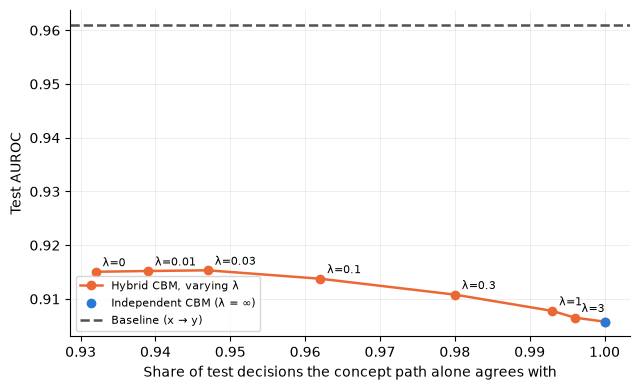

In [72]:
fig, ax = plt.subplots(figsize=(6.5, 4))
finite = tradeoff_report[np.isfinite(tradeoff_report["λ (side penalty)"])]
pure_cbm = tradeoff_report[~np.isfinite(tradeoff_report["λ (side penalty)"])].iloc[0]
ax.plot(tradeoff_report["Decisions explained by concepts"], tradeoff_report["Test AUROC"],
        color=MODEL_COLORS["Hybrid CBM"], marker="o", label="Hybrid CBM, varying λ")
ax.plot([pure_cbm["Decisions explained by concepts"]], [pure_cbm["Test AUROC"]], linestyle="none",
        marker="o", color=MODEL_COLORS["Independent CBM"], label="Independent CBM (λ = ∞)")
for _, row in finite.iterrows():
    ax.annotate(f"λ={row['λ (side penalty)']:g}",
                (row["Decisions explained by concepts"], row["Test AUROC"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(baseline_test_metrics["auroc"], color=MODEL_COLORS["Baseline (x → y)"], linestyle="--",
           label="Baseline (x → y)")
ax.set_xlabel("Share of test decisions the concept path alone agrees with")
ax.set_ylabel("Test AUROC")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Each point is the hybrid trained with a different side-channel penalty λ. The graph shows what you lose in interpretability as you let the side channel do more of the work.
- **λ = ∞** means no side channel at all. That point is the plain independent CBM.
- **λ = 0** is an unconstrained side channel.
- The **x-axis** is an interpretability measure. For each test image the hybrid decides "smiling / not smiling" from `f(c) + s(x)`. The x-axis is the fraction of images where the concept path `f(c)` alone would make the same decision. At 1.00 the concepts explain every decision; at 0.94 the side channel overturns the concepts on 6% of the images.

In [73]:
# Default: the lambda with the best VALIDATION AUROC (lambda = infinity, the pure CBM, is excluded).
# To favour interpretability, set HYBRID_PENALTY by hand to a larger lambda whose validation AUROC is
# within your tolerance of the best, and justify that choice in the report.
HYBRID_PENALTY = None

finite_rows = tradeoff_report[np.isfinite(tradeoff_report["λ (side penalty)"])]
if HYBRID_PENALTY is None:
    HYBRID_PENALTY = float(finite_rows.loc[finite_rows["Validation AUROC"].idxmax(), "λ (side penalty)"])
if HYBRID_PENALTY not in side_heads:
    side_heads[HYBRID_PENALTY] = fit_side_head(SIDE_WEIGHT_DECAY, HYBRID_PENALTY)
print("Hybrid side-channel penalty lambda:", HYBRID_PENALTY)

# Build the hybrid from a fresh copy of the concept predictor (hooks stay on this copy only), then load the
# fitted heads: f_c is the Part 3 label head, s_x is the side head with its standardisation folded in.
hybrid_model = HybridCBM(
    concept_predictor=copy.deepcopy(concept_model),
    num_concepts=NUM_CONCEPTS,
    feature_dim=concept_model.backbone.in_features,
    concept_logit_offset=concept_logit_offset,
).to(device)
hybrid_model.f_c.load_state_dict(independent_head.state_dict())
hybrid_model.s_x.load_state_dict(
    fold_standardization(side_heads[HYBRID_PENALTY], feature_mean, feature_std).state_dict())
hybrid_model.f_c.requires_grad_(False)   # the concept path stays exactly as in Part 3
hybrid_model.eval()

hybrid_side_test = side_logits(side_heads[HYBRID_PENALTY], "test")
hybrid_test_logits = concept_path["test"] + hybrid_side_test

# Sanity check: the full image -> prediction module (hook included) reproduces the cached computation.
_, hybrid_module_logits = predict_logits(hybrid_model, test_loader)
max_gap = (hybrid_module_logits - hybrid_test_logits).abs().max().item()
assert max_gap < 1e-3, f"Module and cached path disagree (max |delta logit| = {max_gap:.2e})"
print(f"Sanity check passed: full hybrid and cached computation agree (max |delta logit| = {max_gap:.1e}).")

Hybrid side-channel penalty lambda: 0.01
[HybridCBM] Hooked into backbone layer: 'backbone.backbone.8'
Sanity check passed: full hybrid and cached computation agree (max |delta logit| = 1.9e-06).


In [74]:
hybrid_test_metrics = binary_scores(test_y, hybrid_test_logits)
hybrid_side_share = (hybrid_side_test.abs().mean()
                     / (hybrid_side_test.abs().mean() + concept_path["test"].abs().mean())).item()
hybrid_concept_agreement = ((concept_path["test"] >= 0) == (hybrid_test_logits >= 0)).float().mean().item()

display(pd.DataFrame([
    score_row("Baseline (x → y)", test_y, baseline_test_logits),
    score_row("Independent CBM (x → c → y)", test_y, main_logits),
    score_row(f"Hybrid CBM (λ = {HYBRID_PENALTY:g})", test_y, hybrid_test_logits),
]).round(4))

print_difference("Hybrid", "CBM", paired_difference_ci(test_y, hybrid_test_logits, main_logits))
print_difference("Hybrid", "baseline", paired_difference_ci(test_y, hybrid_test_logits, baseline_test_logits))

print("----------------------------------")
print("Concept metrics are those of Part 3: the hybrid's concept path is unchanged.")
print(f"Side-channel share of |logit| on test images: {hybrid_side_share:.2f}")
print(f"Test decisions the concept path alone agrees with: {hybrid_concept_agreement:.1%}")
print("----------------------------------")

# Inspect the two pathways for five test images.
display(pd.DataFrame({
    "True Smiling": test_y[:5].int().numpy(),
    "Concept logit f(c)": concept_path["test"][:5].numpy(),
    "Side logit s(x)": hybrid_side_test[:5].numpy(),
    "Final logit": hybrid_test_logits[:5].numpy(),
    "P(Smiling)": torch.sigmoid(hybrid_test_logits[:5]).numpy(),
}).round(4))

,Model,Test accuracy,Accuracy 95% CI,Test AUROC,AUROC 95% CI
0,Baseline (x → y),0.888,"[0.869, 0.908]",0.9610,"[0.950, 0.970]"
1,Independent CBM (x → c → y),0.827,"[0.802, 0.849]",0.9058,"[0.886, 0.924]"
2,Hybrid CBM (λ = 0.01),0.842,"[0.819, 0.862]",0.9152,"[0.897, 0.931]"


Hybrid minus CBM: accuracy +1.50 pp (95% CI +0.00 to +3.00); AUROC +0.0094 (95% CI +0.0016 to +0.0178)
Hybrid minus baseline: accuracy -4.60 pp (95% CI -6.90 to -2.50); AUROC -0.0458 (95% CI -0.0600 to -0.0324)
----------------------------------
Concept metrics are those of Part 3: the hybrid's concept path is unchanged.
Side-channel share of |logit| on test images: 0.32
Test decisions the concept path alone agrees with: 93.9%
----------------------------------


,True Smiling,Concept logit f(c),Side logit s(x),Final logit,P(Smiling)
0,0,-0.7175,0.5954,-0.1221,0.4695
1,0,-2.7690,-2.8612,-5.6302,0.0036
2,1,2.5255,0.1989,2.7244,0.9384
3,1,-1.0627,-0.5243,-1.5870,0.1698
4,1,-0.9668,0.6374,-0.3293,0.4184


### Steerability of the hybrid
The same interventions change only `f(c)`; `s(x)` stays as it is. The left and middle panels repeat the Part 3 accuracy and AUROC curves with the hybrid added. The right panel shows the task RMSE (Koh et al., Fig. 4): for a binary target it is the RMSE between P(Smiling) and the 0/1 label, i.e. the square root of the Brier score (0 = perfect, 0.5 = always answering 0.5). The baseline has no concepts, so it is a flat reference line. Note that it memorised the training set, so its probabilities may be over-confident (near 0 or 1 even when wrong), which inflates its RMSE relative to its error rate: read the RMSE panel as "accuracy plus how honest the probabilities are".

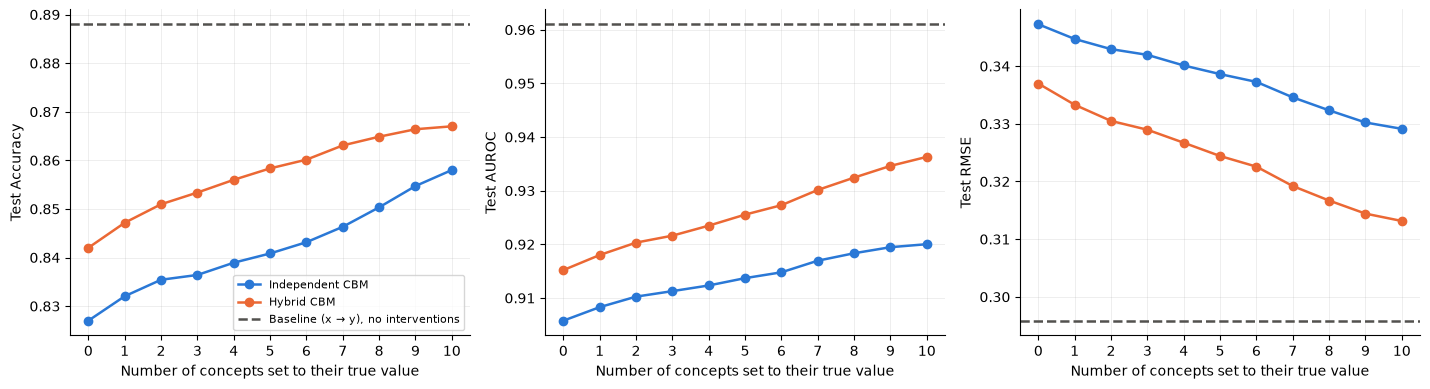

,"Accuracy, k=0","Accuracy, k=2","Accuracy, k=5","Accuracy, k=10",Gain k=0 → all (pp)
Independent CBM,0.827,0.8354,0.8408,0.858,3.1
Hybrid CBM,0.842,0.8510,0.8583,0.867,2.5


,"RMSE, k=0","RMSE, k=2","RMSE, k=5","RMSE, k=10"
Independent CBM,0.3473,0.3429,0.3386,0.3291
Hybrid CBM,0.3370,0.3305,0.3244,0.3131


Baseline RMSE: 0.2959 | baseline error (1 - accuracy): 0.1120


In [75]:
intervention_results["Hybrid CBM"] = intervention_curve(
    lambda c: head_logits(independent_head, c) + hybrid_side_test,
    test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y,
)

baseline_rmse = torch.sqrt((torch.sigmoid(baseline_test_logits) - test_y).pow(2).mean()).item()
baseline_reference = {**baseline_test_metrics, "rmse": baseline_rmse}
plot_interventions(intervention_results, baseline_reference, metrics=("Accuracy", "AUROC", "RMSE"))

display(intervention_table(intervention_results).round(4))

ks = sorted({0, min(2, NUM_CONCEPTS), min(5, NUM_CONCEPTS), NUM_CONCEPTS})
rmse_table = pd.DataFrame({
    name: curve.set_index("Concepts intervened")["RMSE"].loc[ks]
    for name, curve in intervention_results.items()
}).T
rmse_table.columns = [f"RMSE, k={k}" for k in ks]
display(rmse_table.round(4))
print(f"Baseline RMSE: {baseline_rmse:.4f} | baseline error (1 - accuracy): {1 - baseline_test_metrics['accuracy']:.4f}")

#### Part 4: how to read these results
- The side head can only add information that is *linearly readable* from the frozen concept-backbone features; unlike the baseline, it cannot fine-tune the backbone for Smiling. Expect the hybrid to land between the CBM and the baseline.
- Read the trade-off table from λ = ∞ (pure CBM) up to λ = 0: accuracy rises while the side channel's share of the logit rises and the share of decisions the concepts alone explain falls. That is the interpretability cost of the side channel.
- **Steerability:** with all concepts set to their true values, the pure CBM reaches its k = 10 accuracy. In the hybrid, `s(x)` still contributes, so the same intervention moves the output less, and it can even hurt when `s(x)` was compensating for concept errors that the intervention removed. Compare the intervention-gain column across λ.
- Havasi et al. (2022) make the side channel latent, binary and stochastic, and train an amortisation network so that it can be marginalised out when a fully concept-based explanation is needed. That is beyond this assignment, but it is the principled version of what λ approximates here.

---
# Final comparison

,Model,Test accuracy,Accuracy 95% CI,Test AUROC,AUROC 95% CI,Concept mean AUROC,Concept macro-F1,"Accuracy gain, all concepts given (pp)",Side-channel share of |logit|,Decisions explained by concepts
0,Baseline (x → y),0.888,"[0.869, 0.908]",0.9610,"[0.950, 0.970]",NaN,NaN,NaN,NaN,NaN
1,Independent CBM (x → c → y),0.827,"[0.802, 0.849]",0.9058,"[0.886, 0.924]",0.8023,0.4925,3.1,0.0000,1.000
2,Hybrid CBM (λ = 0.01),0.842,"[0.819, 0.862]",0.9152,"[0.897, 0.931]",0.8023,0.4925,2.5,0.3208,0.939


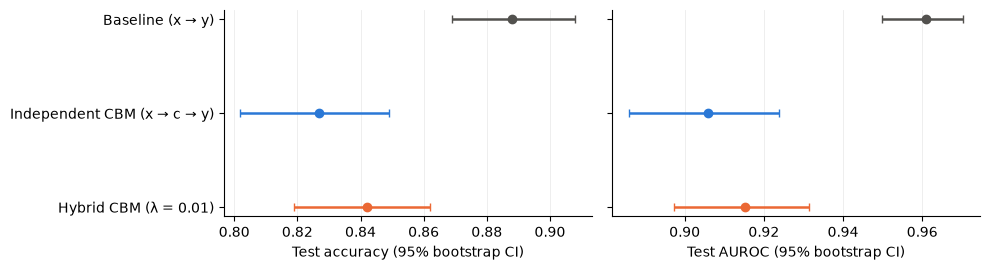

In [76]:
def intervention_gain(name):
    curve = intervention_results[name]
    return 100 * (curve["Accuracy"].iloc[-1] - curve["Accuracy"].iloc[0])


summary_rows = []
for name, color_key, logits, curve_name, side_share, agreement in [
    ("Baseline (x → y)", "Baseline (x → y)", baseline_test_logits, None, np.nan, np.nan),
    ("Independent CBM (x → c → y)", "Independent CBM", main_logits, "Independent CBM", 0.0, 1.0),
    (f"Hybrid CBM (λ = {HYBRID_PENALTY:g})", "Hybrid CBM", hybrid_test_logits, "Hybrid CBM",
     hybrid_side_share, hybrid_concept_agreement),
]:
    scores = binary_scores(test_y, logits)
    accuracy_ci, auroc_ci = bootstrap_ci(test_y, logits)
    has_concepts = curve_name is not None
    summary_rows.append({
        "Model": name,
        "color": MODEL_COLORS[color_key],
        "Test accuracy": scores["accuracy"],
        "Accuracy 95% CI": f"[{accuracy_ci[0]:.3f}, {accuracy_ci[1]:.3f}]",
        "Test AUROC": scores["auroc"],
        "AUROC 95% CI": f"[{auroc_ci[0]:.3f}, {auroc_ci[1]:.3f}]",
        "Concept mean AUROC": cbm_concept_test_metrics["macro_auroc"] if has_concepts else np.nan,
        "Concept macro-F1": cbm_concept_test_metrics["macro_f1"] if has_concepts else np.nan,
        "Accuracy gain, all concepts given (pp)": intervention_gain(curve_name) if has_concepts else np.nan,
        "Side-channel share of |logit|": side_share,
        "Decisions explained by concepts": agreement,
        "_accuracy_ci": accuracy_ci,
        "_auroc_ci": auroc_ci,
    })
final_summary = pd.DataFrame(summary_rows)
display(final_summary.drop(columns=["color", "_accuracy_ci", "_auroc_ci"]).round(4))

# Test accuracy and AUROC with 95% bootstrap intervals, one row per model.
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for axis, metric, ci_column in zip(axes, ["Test accuracy", "Test AUROC"], ["_accuracy_ci", "_auroc_ci"]):
    for position, row in final_summary.iterrows():
        low, high = row[ci_column]
        axis.errorbar(row[metric], position, xerr=[[row[metric] - low], [high - row[metric]]],
                      fmt="o", color=row["color"], capsize=3)
    axis.set_xlabel(f"{metric} (95% bootstrap CI)")
axes[0].set_yticks(range(len(final_summary)))
axes[0].set_yticklabels(final_summary["Model"])
axes[0].invert_yaxis()
axes[0].grid(axis="y", visible=False)
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()